# 🐛 Python Source Code Bug Summarizer using CodeBERT (Hybrid Pipeline)

**NLP Assignment — Semester 7**

---

## 1. Introduction and problem statement
This notebook fine-tunes **CodeBERT** (`microsoft/codebert-base`) to act as the ML component of our hybrid bug classifier.
While static tools (AST/Pyflakes) and restricted dynamic execution handle explicit errors (Syntax, Indentation, Undefined Variables), CodeBERT is tasked with finding **logical bugs** such as `off_by_one`, `wrong_comparison`, and `missing_return`.

The pipeline combines these to handle a wide range of Python bugs.


## 2. Install libraries and check the GPU

In [1]:
import torch
import sys

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    device = torch.device("cuda")
else:
    print("WARNING: No GPU found. Training on CPU will be slow.")
    device = torch.device("cpu")

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import Dataset, DatasetDict
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries imported successfully!")

PyTorch version: 2.14.1+cu126


CUDA available: True
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


Libraries imported successfully!


## 3. Load and explore the dataset

Dataset size: (22500, 3)


,code,bug_type,split
0,"class FakeHandler:\n\n def __init__(self, i...",no_bug,train
1,"def doit1(level, pen):\n pen.hideturtle()\n...",no_bug,train
2,"class getlang_Tests(unittest.TestCase):\n ""...",no_bug,train
3,class RawConfigParserTestCaseNonStandardDelimi...,no_bug,train
4,"def _is_parent(dir_a, dir_b):\n """"""\n Re...",no_bug,train


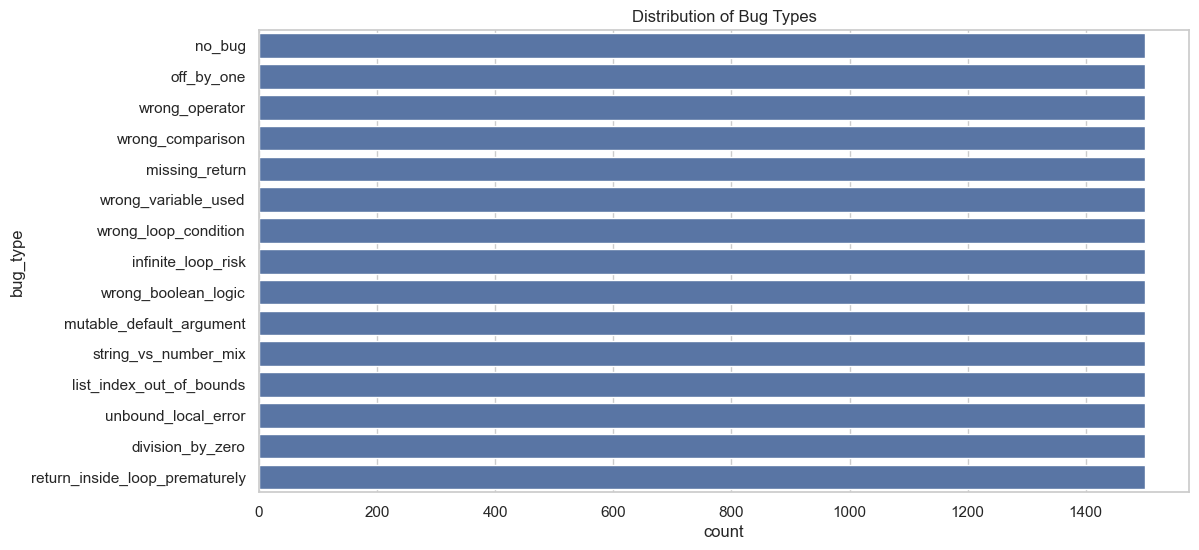

In [2]:
data_path = '../data/bug_dataset.csv'
if not os.path.exists(data_path):
    data_path = 'data/bug_dataset.csv'
df = pd.read_csv(data_path)
print(f"Dataset size: {df.shape}")
display(df.head())

# Class distribution
plt.figure(figsize=(12, 6))
sns.countplot(y='bug_type', data=df, order=df['bug_type'].value_counts().index)
plt.title("Distribution of Bug Types")
plt.show()

## 4. Preprocess and tokenize

In [3]:
MODEL_NAME = "microsoft/codebert-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Create label mapping
labels = df['bug_type'].unique().tolist()
label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}
print("Labels:", label2id)

# Apply mapping
df['label'] = df['bug_type'].map(label2id)

# Split dataset
train_df = df[df['split'] == 'train']
val_df = df[df['split'] == 'val']
test_df = df[df['split'] == 'test']

# Convert to Hugging Face Dataset
train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)
test_dataset = Dataset.from_pandas(test_df)

dataset = DatasetDict({
    'train': train_dataset,
    'validation': val_dataset,
    'test': test_dataset
})

# Tokenization function
def tokenize_function(examples):
    return tokenizer(examples['code'], padding="max_length", truncation=True, max_length=256)

tokenized_datasets = dataset.map(tokenize_function, batched=True)
tokenized_datasets.set_format("torch", columns=['input_ids', 'attention_mask', 'label'])
print("Tokenization complete.")

Labels: {'no_bug': 0, 'off_by_one': 1, 'wrong_operator': 2, 'wrong_comparison': 3, 'missing_return': 4, 'wrong_variable_used': 5, 'wrong_loop_condition': 6, 'infinite_loop_risk': 7, 'wrong_boolean_logic': 8, 'mutable_default_argument': 9, 'string_vs_number_mix': 10, 'list_index_out_of_bounds': 11, 'unbound_local_error': 12, 'division_by_zero': 13, 'return_inside_loop_prematurely': 14}


Map:   0%|          | 0/18114 [00:00<?, ? examples/s]

Map:   0%|          | 0/2085 [00:00<?, ? examples/s]

Map:   0%|          | 0/2301 [00:00<?, ? examples/s]

Tokenization complete.


## 5. Load CodeBERT and fine-tune

In [4]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, 
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id
)

training_args = TrainingArguments(
    output_dir="./results",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    fp16=torch.cuda.is_available(),
    logging_steps=50,
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, average='weighted')
    return {"accuracy": acc, "f1": f1}

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

print("Starting training...")
trainer.train()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: microsoft/codebert-base
Key                        | Status     | 
---------------------------+------------+-
pooler.dense.weight        | UNEXPECTED | 
pooler.dense.bias          | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting training...


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,1.388453,0.672896,0.788969,0.792956
2,1.172828,0.609549,0.805755,0.816277
3,0.959723,0.606169,0.811511,0.816075


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3399, training_loss=1.395336254374635, metrics={'train_runtime': 705.2225, 'train_samples_per_second': 77.057, 'train_steps_per_second': 4.82, 'total_flos': 7149824927898624.0, 'train_loss': 1.395336254374635, 'epoch': 3.0})

## 6. Evaluate the results on Test Set

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.959723,0.496028,3,0.855715,0.858336


Test Accuracy: 0.8557
Test F1 Score: 0.8583



Classification Report:
                                precision    recall  f1-score   support

                        no_bug       0.67      0.71      0.69       150
                    off_by_one       0.84      0.83      0.83       158
                wrong_operator       0.89      0.81      0.85       152
              wrong_comparison       0.80      0.83      0.81       123
                missing_return       0.76      0.79      0.77       153
           wrong_variable_used       0.90      0.82      0.86       159
          wrong_loop_condition       0.64      0.84      0.73       162
            infinite_loop_risk       0.94      0.87      0.91       154
           wrong_boolean_logic       0.85      0.92      0.88       146
      mutable_default_argument       0.99      1.00      1.00       156
          string_vs_number_mix       0.95      0.92      0.94       152
      list_index_out_of_bounds       0.93      0.87      0.90       151
           unbound_local_error       0.

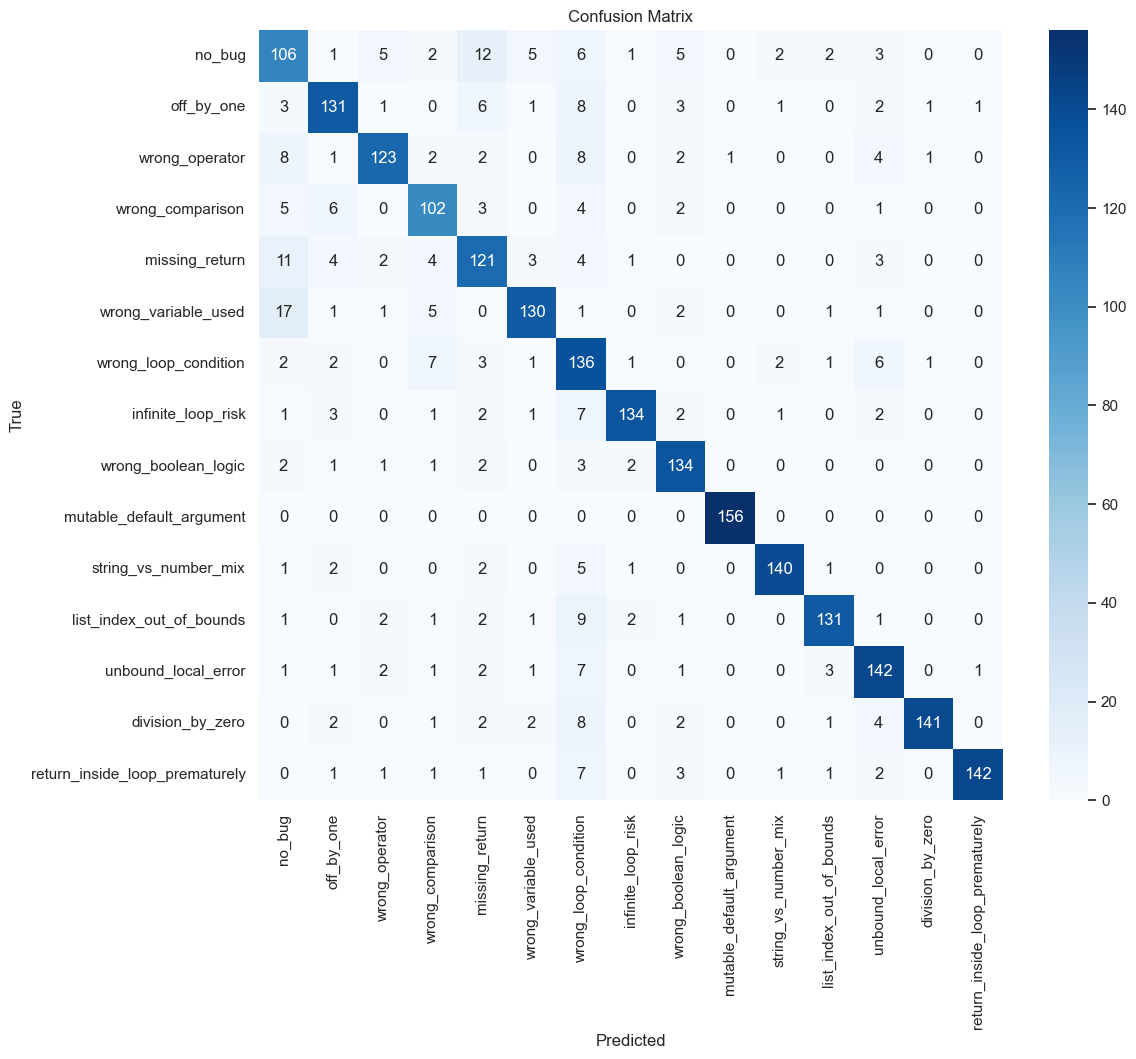

In [5]:
# Evaluate on test set
eval_results = trainer.evaluate(tokenized_datasets["test"])
print(f"Test Accuracy: {eval_results['eval_accuracy']:.4f}")
print(f"Test F1 Score: {eval_results['eval_f1']:.4f}")

# Get predictions
predictions = trainer.predict(tokenized_datasets["test"])
preds = np.argmax(predictions.predictions, axis=-1)
y_true = predictions.label_ids

print("\nClassification Report:")
print(classification_report(y_true, preds, target_names=labels))

# Confusion Matrix
cm = confusion_matrix(y_true, preds)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

## 7. Save Model

In [6]:
import os

output_dir = "../model/codebert_bug_model"
if not os.path.exists("../model"):
    output_dir = "model/codebert_bug_model"
os.makedirs(output_dir, exist_ok=True)

trainer.save_model(output_dir)
tokenizer.save_pretrained(output_dir)

# Save label mapping
with open(os.path.join(output_dir, "label_mapping.json"), "w") as f:
    json.dump({
        "label_to_id": label2id,
        "id_to_label": id2label
    }, f)

print(f"Model and tokenizer saved to {output_dir}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved to ../model/codebert_bug_model


## 8. Limitations

The hybrid approach correctly mitigates the weaknesses of ML-only bug detection by deferring exact errors (syntax/runtime) to standard tools. However, there are still limitations to this system:
1. **Intent-based Bugs**: The system cannot detect bugs where the code successfully compiles and executes logic flawlessly, but the logic simply does not match the developer's abstract intent (e.g. implementing a BFS instead of a DFS).
2. **Context constraints**: CodeBERT operates on a 256-token limit here. Bugs spanning multiple files or deep class hierarchies are truncated.
3. **Synthetic distribution**: The mutation strategies generate realistic patterns but may lack the nuanced mistakes seen in massive open-source commits.
